# One Model Per Group Across a Ray Cluster Using `fit_group`

Suppose you sell a product in 40 stores and want to know, for each store, how much sales drop when the price goes up; This is known as the store's *price elasticity*. A simple Bayesian approach is to fit the same small PyMC model to each store's data separately.

Fitting stores one at a time gets slow when there are many of them, think about how many Walmart's there are across the nation. `pymc_ray.fit_grouped` fits them in parallel with [Ray](https://www.ray.io),  on a cluster, and returns one posterior per store.

In this notebook we simulate some data, write the model for one store, fit every store, and then check the results.

In [1]:
import os

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import ray

import pymc_ray as pmr

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.facecolor": "w",
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)

## Start Ray

`ray.init()` starts Ray on this machine and uses all of its CPUs. `log_to_driver=False` keeps the workers' logs out of the notebook.

To use a cluster instead, set the `RAY_ADDRESS` environment variable to the cluster's [Ray Client](https://docs.ray.io/en/latest/cluster/running-applications/job-submission/ray-client.html)
address (for example `ray://localhost:10001`) before starting Jupyter. `runtime_env` then installs this notebook's PyMC version on the cluster and copies `pymc_ray` there.

In [2]:
ray_address = os.environ.get("RAY_ADDRESS")  # None: start Ray on this machine
runtime_env = {"pip": [f"pymc=={pm.__version__}", "narwhals>=2"], "py_modules": [pmr]} if ray_address else None
ray.init(address=ray_address, runtime_env=runtime_env, log_to_driver=False)
print(f"Ray is using {ray.cluster_resources()['CPU']:.0f} CPUs")

2026-10-28 05:18:00,776	INFO worker.py:1841 -- Started a local Ray instance.


Ray is using 14 CPUs


## Simulate some data

Each store gets its own baseline sales and its own elasticity. We draw them at random, so we know the true values and can check our estimates against them later. Price and sales are on the log scale, so an elasticity of -1.5 means that a 1% price increase lowers sales by about 1.5%.

Real data are rarely clean, so we also delete one of store_07's prices.

In [3]:
rng = np.random.default_rng(0)
n_stores = 40
n_weeks = 104
stores = [f"store_{i:02d}" for i in range(n_stores)]

true_elasticity = pd.Series(rng.normal(-1.5, 0.4, n_stores), index=stores)
baseline = rng.normal(5.0, 0.5, n_stores)

store = np.repeat(np.arange(n_stores), n_weeks)  # Store integer id
log_price = rng.normal(0.0, 0.2, store.size)
log_units = baseline[store] + true_elasticity.to_numpy()[store] * log_price + rng.normal(0.0, 0.3, store.size)
sales_df = pd.DataFrame({"store": np.array(stores)[store], "log_price": log_price, "log_units": log_units})
sales_df.loc[7 * n_weeks, "log_price"] = np.nan  # a missing price in store_07
sales_df.head()

,store,log_price,log_units
0,store_00,0.037704,4.423654
1,store_00,-0.126639,4.222428
2,store_00,-0.075513,4.782417
3,store_00,-0.218229,4.901965
4,store_00,-0.255536,5.411312


## The model for one store

`fit_grouped` needs a function that takes **one store's data** and returns a PyMC model:

- The **priors** describe what we believe before seeing any data, in this case, log-sales around 5, and an elasticity that is probably negative.
- The **likelihood** (the variable with `observed=`) ties the parameters to the sales we observed.

In [5]:
def elasticity_model(df: pd.DataFrame) -> pm.Model:
    """The model for one store. `df` holds ONLY that store's rows."""
    with pm.Model() as model:
        # Priors
        alpha = pm.Normal("alpha", 5, 2)  # log-sales at the usual price
        elasticity = pm.Normal("elasticity", -1, 1)  # sales change per 1% price change
        sigma = pm.HalfNormal("sigma", 1)  # week-to-week noise
        # Likelihood
        mu = alpha + elasticity * df["log_price"].to_numpy()
        pm.Normal("log_units", mu, sigma, observed=df["log_units"].to_numpy())
    return model

Let's build the model for one store first, to check that it looks right:

In [6]:
elasticity_model(sales_df[sales_df["store"] == "store_00"])

## Fit every store

`fit_grouped` splits `sales_df` by the `store` column and samples `elasticity_model` for every store in parallel. `fit_kwargs` are passed on to `pm.sample`. 

In addition:

- `postprocess_fn` runs on the worker right after a store is fit, while its model is still there. We use it to simulate sales from the fitted model (posterior predictive samples) to compare with the real sales later.

- `on_error="warn"` reports a store that fails and carries on with the others. The default, `"raise"`, stops at the first failure.
- `random_seed` makes the run reproducible. Each store gets its own seeds, derived from this one and the store's name. One for sampling, and one that `postprocess_fn` receives for the simulations.

In [7]:
def add_predictions(store, model, idata, random_seed):
    """Runs on the worker after each store is fit."""
    return pm.sample_posterior_predictive(idata, model=model, extend_inferencedata=True, random_seed=random_seed, progressbar=False)


results = pmr.fit_grouped(
    sales_df,
    group_by="store",
    model_fn=elasticity_model,
    fit_kwargs={
        "draws": 1000,
        "tune": 1000,
        "chains": 4,
    },
    postprocess_fn=add_predictions,
    on_error="warn",
    random_seed=42,
)
results

Fitting groups:   0%|          | 0/40 [00:00<?, ?it/s]

/var/folders/qv/63yqp4p50630y7pqfgcbgtq80000gn/T/ipykernel_9328/3594853214.py:8: UserWarning: Fitting group 'store_07' failed: SamplingError("Initial evaluation of model at starting point failed!\nStarting values:\n{'alpha': array(5.25000255), 'elasticity': array(-1.78890597), 'sigma_log__': array(0.41888541)}\n\nLogp initial evaluation results:\n{'alpha': np.float64(-1.62), 'elasticity': np.float64(-1.23), 'sigma': np.float64(-0.96), 'log_units': np.float64(nan)}\nYou can call `model.debug()` for more details.")
  results = pmr.fit_grouped(


GroupedResults(39 fitted, 1 failed)

## Look at the results

`results` works like a dictionary, where the keys are store names, and each value is that store's posterior, the same `DataTree` that `pm.sample` returns.

In [8]:
az.summary(results["store_00"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,4.3764,0.031,4.3,4.4,6502,3318,1.00,0.00039,0.00053
elasticity,-1.458,0.166,-1.7,-1.2,5247,3075,1.00,0.0023,0.0028
sigma,0.3197,0.0227,0.29,0.36,5124,2903,1.00,0.00032,0.00039


`results.summary()` combines the summaries of all stores in one table. With many stores,
it is easiest to look at one parameter at a time:

In [9]:
results.summary(var_names=["elasticity"]).head()

,,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
store,variable,,,,,,,,,
store_00,elasticity,-1.458179,0.165705,-1.723128,-1.195238,5247.470664,3075.940980,1.001715,0.002290,0.002787
store_01,elasticity,-1.684536,0.132439,-1.899386,-1.474487,5536.950516,2821.539090,1.001503,0.001779,0.002353
store_02,elasticity,-1.190146,0.169798,-1.467195,-0.919679,5110.001035,2918.903527,1.000317,0.002380,0.002971
store_03,elasticity,-1.299176,0.127366,-1.497001,-1.095095,6469.223241,3245.606640,1.001056,0.001584,0.002001
store_04,elasticity,-1.607368,0.150046,-1.842864,-1.367335,6007.820447,3381.462732,1.000855,0.001940,0.002163


## Stores that failed

One store failed. `results.failures` lists the stores that failed, each with its error message (`.error`) and the full traceback from the worker (`.traceback`):

In [10]:
list(results.failures)

['store_07']

In [11]:
results.failures["store_07"]

GroupFailure(key='store_07', error='SamplingError("Initial evaluation of model at starting point failed!\\nStarting values:\\n{\'alpha\': array(5.25000255), \'elasticity\': array(-1.78890597), \'sigma_log__\': array(0.41888541)}\\n\\nLogp initial evaluation results:\\n{\'alpha\': np.float64(-1.62), \'elasticity\': np.float64(-1.23), \'sigma\': np.float64(-0.96), \'log_units\': np.float64(nan)}\\nYou can call `model.debug()` for more details.")', traceback='Traceback (most recent call last):\n  File "/Users/dekermanjian/Desktop/Projects/pymc-ray/src/pymc_ray/grouped.py", line 237, in __call__\n    result = self.fit_fn(model=model, random_seed=fit_seed, **self.fit_kwargs)\n             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^\n  File "/opt/miniconda3/envs/pymc-ray-312/lib/python3.12/site-packages/pymc/sampling/mcmc.py", line 1037, in sample\n    initial_points, step = init_nuts(\n                           ^^^^^^^^^^\n  File "/opt/miniconda3/envs/pymc-ray-312/lib

In [12]:
print(results.failures["store_07"].traceback)

Traceback (most recent call last):
  File "/Users/dekermanjian/Desktop/Projects/pymc-ray/src/pymc_ray/grouped.py", line 237, in __call__
    result = self.fit_fn(model=model, random_seed=fit_seed, **self.fit_kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/miniconda3/envs/pymc-ray-312/lib/python3.12/site-packages/pymc/sampling/mcmc.py", line 1037, in sample
    initial_points, step = init_nuts(
                           ^^^^^^^^^^
  File "/opt/miniconda3/envs/pymc-ray-312/lib/python3.12/site-packages/pymc/sampling/mcmc.py", line 1872, in init_nuts
    initial_points = _init_jitter(
                     ^^^^^^^^^^^^^
  File "/opt/miniconda3/envs/pymc-ray-312/lib/python3.12/site-packages/pymc/sampling/mcmc.py", line 1749, in _init_jitter
    model.check_start_vals(point)
  File "/opt/miniconda3/envs/pymc-ray-312/lib/python3.12/site-packages/pymc/model/core.py", line 1396, in check_start_vals
    raise SamplingError(
pymc.exceptions.Samp

The warning printed during the fit shows that the problem was the starting point, the log-probability of `log_units` was `nan`, so sampling could not start. That comes from
the missing price. In practice you would fix the data (imputation) and fit again. Since each store's seed depends only on `random_seed` and the store's name, the other
stores would get exactly the same results. Here we simply carry on with the 39 stores that worked.

## Check that sampling worked

The workers' logs are hidden, so we look for problems ourselves. Common rules of thumb: `r_hat` below 1.01, an effective sample size (`ess_bulk`) above 400, and no divergences.

In [13]:
summary = results.summary()
summary[(summary["r_hat"] > 1.01) | (summary["ess_bulk"] < 400)]

,,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
store,variable,,,,,,,,,


In [14]:
divergences = pd.Series({store: int(idata.sample_stats["diverging"].sum()) for store, idata in results.items()})
divergences[divergences > 0]

Series([], dtype: int64)

## Compare with the true values

We simulated the data, so we know each store's true elasticity. Each point below is one store's estimate (posterior mean) with its 89% interval, ArviZ's default. Points close to the dashed line are good estimates, and about 89% of the intervals should contain the true value.

92% of the 89% intervals contain the true elasticity


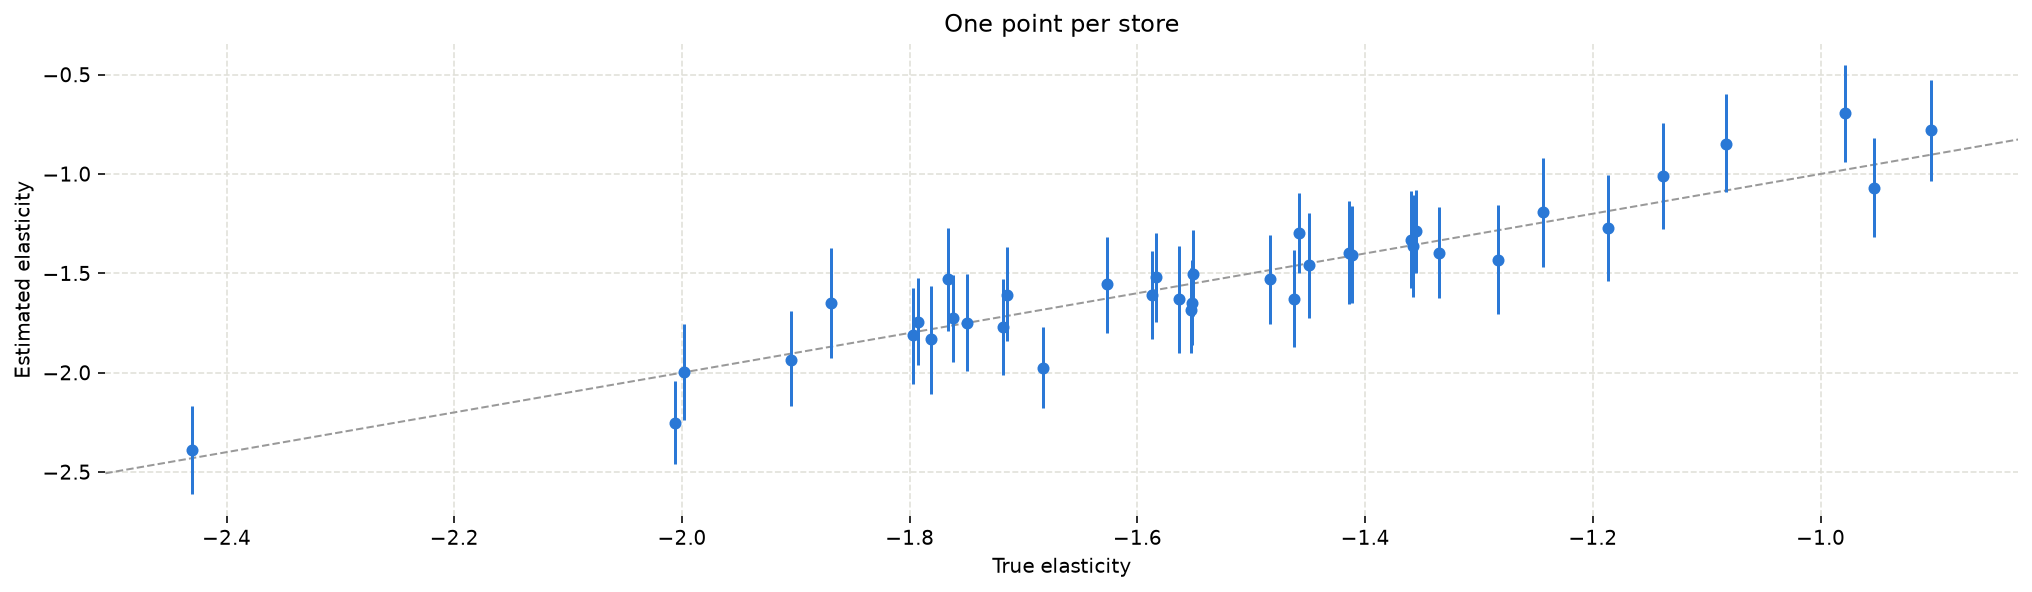

In [15]:
est = results.summary(var_names=["elasticity"]).droplevel("variable")
truth = true_elasticity[est.index]
covered = ((est["eti89_lb"] <= truth) & (truth <= est["eti89_ub"])).mean()
print(f"{covered:.0%} of the 89% intervals contain the true elasticity")

fig, ax = plt.subplots()
ax.axline((-1.5, -1.5), slope=1, color="0.6", lw=1, ls="--")
ax.errorbar(
    truth,
    est["mean"],
    yerr=[est["mean"] - est["eti89_lb"], est["eti89_ub"] - est["mean"]],
    fmt="o",
    ms=5,
    lw=1.5,
    color="#2a78d6",
)
ax.set(
    xlabel="True elasticity",
    ylabel="Estimated elasticity",
    title="One point per store",
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)

## Posterior predictive check

If the model describes the data well, sales simulated from it should look like the real sales data. `add_predictions` already stored those simulations with each store's results. Each thin blue line is the distribution of one set of simulated sales, and the black line is the distribution of the real sales.

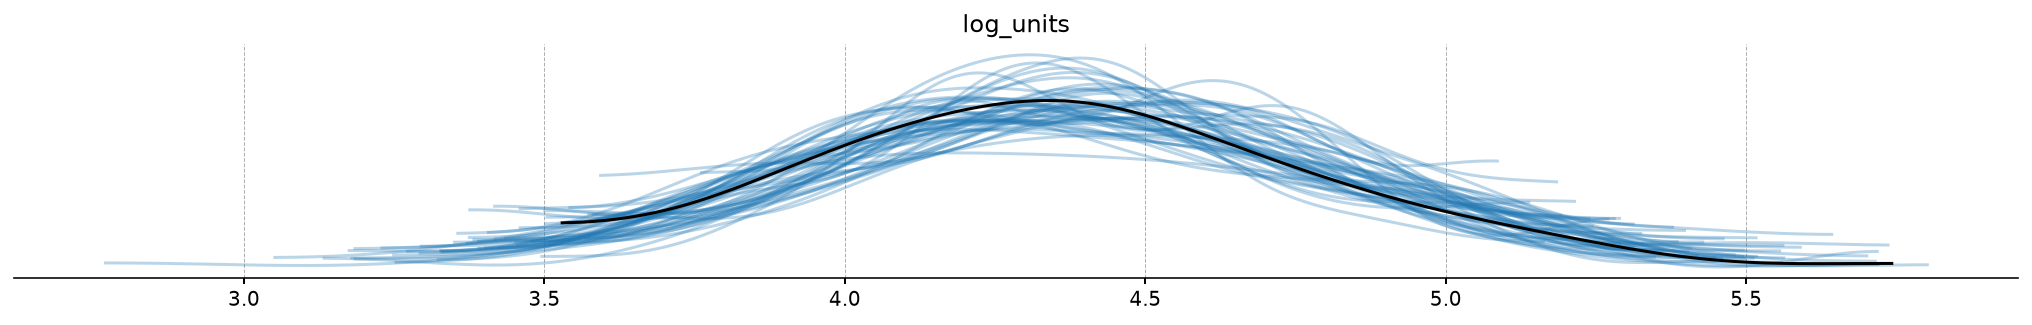

In [14]:
az.plot_ppc_dist(results["store_00"]);

## Additional Features Not Shown in This Tutorial

- **More CPUs per store.** By default each store uses one CPU and runs its chains one after another, and the speed comes from fitting many stores at once. If you have more CPUs than stores, add `"cores": 4` to `fit_kwargs` to run each store's 4 chains in parallel.

- **More data than fits in memory.** Pass a Ray Dataset, such as `ray.data.read_parquet(...)`, instead of a DataFrame, so each store's rows are loaded on the workers. Use `postprocess_fn` to save each posterior to storage and return its path. See [grouped_models.py](grouped_models.py).

In [16]:
ray.shutdown()